### Initialization
Add the Surrogate Modeling module and setup the notebook

In [31]:
# Boilerplate for automatic reloading of modules on run and connecting to paths of local code.

%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import torch
import numpy as np

from SurrogateModels import cokriging

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


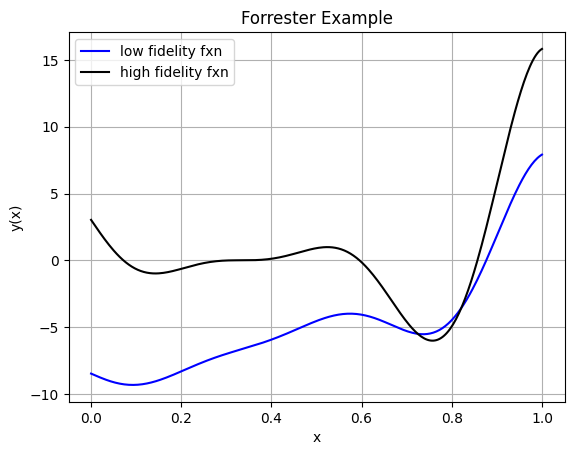

In [32]:
import multi_fidelity_functions
import matplotlib.pyplot as plt

mf_example = multi_fidelity_functions.ForresterExample()
mf_example.plot_functions_1d(name = mf_example.name)
plt.grid()
plt.show()

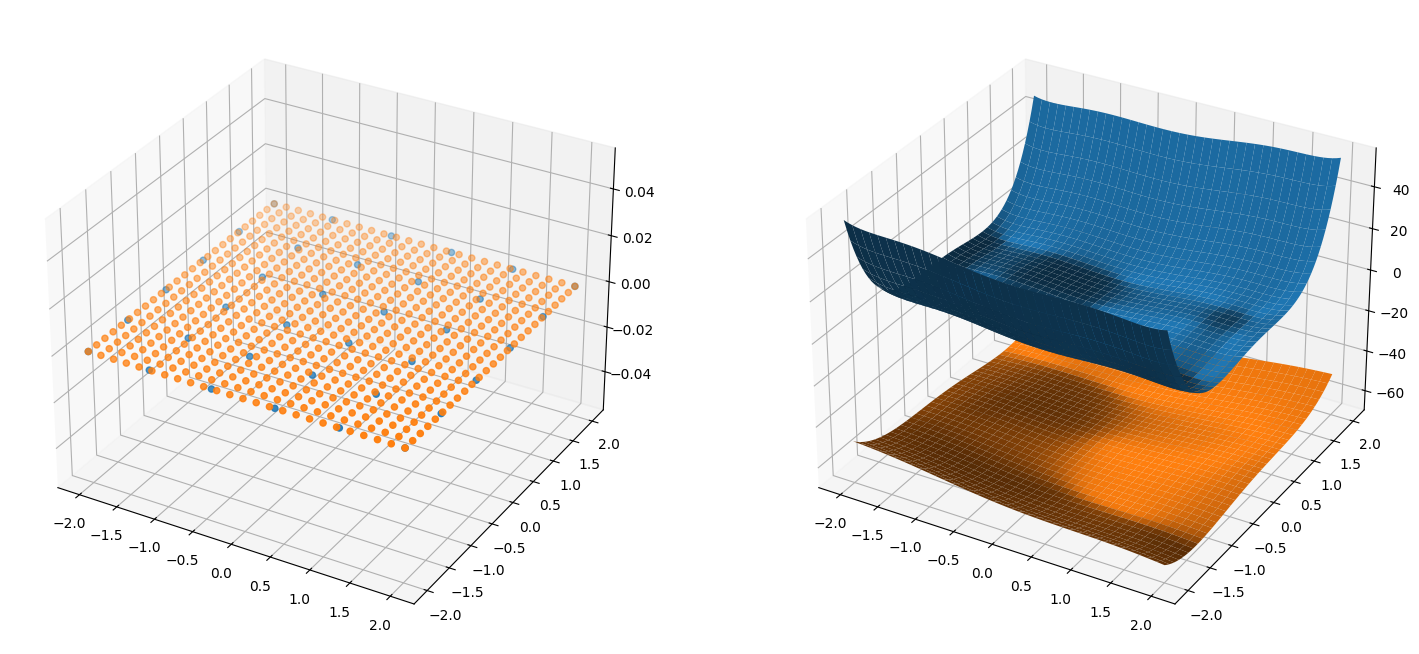

In [ ]:
import multi_fidelity_functions as mff
import matplotlib.pyplot as plt
from SurrogateModels import cokriging

n_hf = 6
n_lf = 25
n_samp = 75

mf_2d = mff.ZhangExample6()

bounds = mf_2d.bounds
x1min = bounds[0][0]
x1max = bounds[0][1]
x2min = bounds[1][0]
x2max = bounds[1][1]

x_hf = mff.generate_grid_array(x1min, x1max, x2min, x2max, n_hf)
x_lf = mff.generate_grid_array(x1min, x1max, x2min, x2max, n_lf)
y_hf = mf_2d.high_fidelity(x_hf)
y_lf = mf_2d.low_fidelity(x_lf)

# take samples for plotting ground truth function
x_samp = mff.generate_grid_array(x1min, x1max, x2min, x2max, n_samp)
y_samp_hf = mf_2d.high_fidelity(x_samp)
y_samp_lf = mf_2d.low_fidelity(x_samp)

# Set figure size for plots
fig = plt.figure(figsize=(18,12))

# Plot the data
ax = fig.add_subplot(121, projection="3d")

sc = ax.scatter(x_hf[:, 0], x_hf[:, 1],y_hf, label="hf_data")
sc = ax.scatter(x_lf[:, 0], x_lf[:, 1],y_lf, label="lf_data")
ax.legend()
# Plot the actual surfaces of the lf and hf functions

X1, X2 = mff.generate_grid(x1min, x1max, x2min, x2max, n_samp)

y_samp_hf = y_samp_hf.reshape(n_samp,n_samp)
y_samp_lf = y_samp_lf.reshape(n_samp,n_samp)

ax = fig.add_subplot(122, projection="3d")
ax.plot_surface(X1, X2, y_samp_hf,label="hf fxn")
ax.plot_surface(X1, X2, y_samp_lf,label="lf fxn")
ax.legend()

plt.show()

### Cokriging Forrester 2007 Recreation

Use the cokriging model class to recreate the Forrester paper example with a fixed scaling factor.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from SurrogateModels import mfs_functions, cokriging

# Start with a synthetic dataset
rng = np.random.RandomState(0)
fxn_ind = 1
dim,xmin,xmax=mfs_functions.function_bounds(fxn_ind)

n_lf = 30
n_hf = 6

x_lf = np.zeros((n_lf,dim), dtype=float)
x_hf = np.zeros((n_hf,dim), dtype=float)

# Generate the analytical functions
hf_fxn = mfs_functions.expensive_fxn(1)
lf_fxn = mfs_functions.cheap_fxn(1)


x_lf[:,0] = np.linspace(xmin,xmax,n_lf)
y_lf = lf_fxn.evaluate(x_lf)
x_hf[:,0] = np.linspace(xmin,xmax,n_hf)
y_hf = hf_fxn.evaluate(x_hf)
model = cokriging.CoKriging(x_lf,y_lf,x_hf,y_hf,True)

x_vals = np.zeros((300,1))
x_vals[:,0] = np.linspace(0,1,300)

#plot the model information
plot_name = "Analytical Models"    
hf_fxn.plot_model(x_vals, plot_name, color = "blue",
                  linestyle = 'solid', label = "hf_fxn")
lf_fxn.plot_model(x_vals, plot_name, color = "black",
                  linestyle = 'dashed', label = "lf_fxn")

plot_name = "Cokriging Model"
hf_fxn.plot_model(x_vals,plot_name, color = "blue",
                  linestyle = (0, (5, 10)), label = "hf_fxn")
lf_fxn.plot_model(x_vals,plot_name, color = "black",
                  linestyle = (0, (5, 10)), label = "lf_fxn")
model.plot_data(plot_name, color_lf="black", color_hf="blue", 
                label_hf = "HF", label_lf = "LF",
                marker_hf = '^',marker_lf="s")
model.plot_model(x_vals,name=plot_name,color="red",
                   label = "CoKriging", linestyle='solid')
model.kriging_hf.plot_model(x_vals, name=plot_name, color="blue",
                    label = "HF Kriging", linestyle='dotted')
model.kriging_lf.plot_model(x_vals, name=plot_name, color="black",
                    label = "LF Kriging", linestyle='dashed')
plt.show()

### Cokriging LF Sample size change

Test the cokriging formulation on different sample sizes to test stability.

In [ ]:
# Start with a synthetic dataset
rng = np.random.RandomState(0)
fxn_ind = 2
dim, xmin, xmax = mfs_functions.function_bounds(fxn_ind)

n_lf = 11
n_hf = 4

x_lf = np.zeros((n_lf, dim), dtype=float)
x_hf = np.zeros((n_hf, dim), dtype=float)

# Generate the analytical functions
hf_fxn = mfs_functions.expensive_fxn(fxn_ind)
lf_fxn = mfs_functions.cheap_fxn(fxn_ind)


x_lf[:, 0] = np.linspace(xmin, xmax, n_lf)
y_lf = lf_fxn.evaluate(x_lf)
x_hf[:, 0] = np.linspace(xmin, xmax, n_hf)
y_hf = hf_fxn.evaluate(x_hf)
model = cokriging.CoKriging(x_lf, y_lf, x_hf, y_hf)

x_vals = np.ones((300, 1))
x_vals[:, 0] = np.linspace(0, 1, 300)

# plot the model information
plot_name = "Analytical Models"
hf_fxn.plot_model(x_vals, plot_name, color="blue", linestyle="solid", label="hf_fxn")
lf_fxn.plot_model(x_vals, plot_name, color="black", linestyle="dashed", label="lf_fxn")

plot_name = "Cokriging Model"
hf_fxn.plot_model(
    x_vals, plot_name, color="blue", linestyle=(0, (5, 10)), label="hf_fxn"
)
lf_fxn.plot_model(
    x_vals, plot_name, color="black", linestyle=(0, (5, 10)), label="lf_fxn"
)
model.plot_data(
    plot_name,
    color_lf="black",
    color_hf="blue",
    label_hf="HF",
    label_lf="LF",
    marker_hf="^",
    marker_lf="s",
)
model.plot_model(
    x_vals, name=plot_name, color="red", label="Cokriging", linestyle="solid"
)
model.kriging_hf.plot_model(
    x_vals, name=plot_name, color="blue", label="HF Kriging", linestyle="dotted"
)
model.kriging_lf.plot_model(
    x_vals, name=plot_name, color="black", label="LF Kriging", linestyle="dashed"
)
plt.show()

### 3 Dimensional Dataset

Run Cokriging on 3D dataset (2 input, 1 output)

In [ ]:
# Start with a synthetic dataset
rng = np.random.RandomState(0)
fxn_ind = 5
dim, xmin, xmax = mfs_functions.function_bounds(fxn_ind)

n_lf = 11
n_hf = 4

x_lf = np.zeros((n_lf, dim), dtype=float)
x_hf = np.zeros((n_hf, dim), dtype=float)

# Generate the analytical functions
hf_fxn = mfs_functions.expensive_fxn(fxn_ind)
lf_fxn = mfs_functions.cheap_fxn(fxn_ind)


x_lf[:, 0] = np.linspace(xmin, xmax, n_lf)
y_lf = lf_fxn.evaluate(x_lf)
x_hf[:, 0] = np.linspace(xmin, xmax, n_hf)
y_hf = hf_fxn.evaluate(x_hf)
model = cokriging.CoKriging(x_lf, y_lf, x_hf, y_hf)

x_vals = np.ones((300, 1))
x_vals[:, 0] = np.linspace(0, 1, 300)

# plot the model information
plot_name = "Analytical Models"
hf_fxn.plot_model(x_vals, plot_name, color="blue", linestyle="solid", label="hf_fxn")
lf_fxn.plot_model(x_vals, plot_name, color="black", linestyle="dashed", label="lf_fxn")

plot_name = "Cokriging Model"
hf_fxn.plot_model(
    x_vals, plot_name, color="blue", linestyle=(0, (5, 10)), label="hf_fxn"
)
lf_fxn.plot_model(
    x_vals, plot_name, color="black", linestyle=(0, (5, 10)), label="lf_fxn"
)
model.plot_data(
    plot_name,
    color_lf="black",
    color_hf="blue",
    label_hf="HF",
    label_lf="LF",
    marker_hf="^",
    marker_lf="s",
)
model.plot_model(
    x_vals, name=plot_name, color="red", label="Cokriging", linestyle="solid"
)
model.kriging_hf.plot_model(
    x_vals, name=plot_name, color="blue", label="HF Kriging", linestyle="dotted"
)
model.kriging_lf.plot_model(
    x_vals, name=plot_name, color="black", label="LF Kriging", linestyle="dashed"
)
plt.show()

In [ ]:
import numpy as np

def some_function(x):
    #return f
    return np.where((x[0]>4), 2*x[0]*x[1],
           4*x[0]*x[1])
scalar = [3,1]
vector = np.array([[1,3,4,6,7],[2,4,5,4,9]])
#vector = vector.transpose()
print(vector)

scalar_val = some_function(scalar)
print(scalar_val)
vector_val = some_function(vector)
print(vector_val)